# Michaelis-Menten: Tau Hybrid Convergence Study
***
## Setup the Environment
***

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
from copy import deepcopy
sys.path.insert(1, os.path.abspath(os.path.join(os.getcwd(), '../')))

In [3]:
import gillespy3d_pp as gillespy2

In [4]:
import matplotlib.pyplot as plt

In [5]:
gillespy2.__file__

'/Users/anisgolriz/Desktop/GillesPy3D/simulation_lib/gillespy3d_pp/__init__.py'

In [6]:
def create_michaelis_menten(sub0=301, enz0=120, rate1=0.0017, rate2=0.5, rate3=0.1, end_t=100):
    # Initialize Model
    model = gillespy2.Model(name="Michaelis_Menten",)

    # Define Variables (GillesPy2.Species)
    A = gillespy2.Species(name='Substrate', initial_value=sub0,mode='dynamic')
    B = gillespy2.Species(name='Enzyme', initial_value=enz0,mode='dynamic')
    C = gillespy2.Species(name='Enzyme_Substrate_Complex', initial_value=0,mode='dynamic')
    D = gillespy2.Species(name='Product', initial_value=0,mode='dynamic')

    # Add Variables to Model
    model.add_species([A, B, C, D])

    # Define Parameters
    p1 = gillespy2.Parameter(name='rate1', expression=rate1)
    p2 = gillespy2.Parameter(name='rate2', expression=rate2)
    p3 = gillespy2.Parameter(name='rate3', expression=rate3)

    # Add Parameters to Model
    model.add_parameter([p1, p2, p3])

    # Define Reactions
    r1 = gillespy2.Reaction(
        name="r1", reactants={'Substrate': 1, 'Enzyme': 1},
        products={'Enzyme_Substrate_Complex': 1}, rate='rate1'
    )
    r2 = gillespy2.Reaction(
        name="r2", reactants={'Enzyme_Substrate_Complex': 1},
        products={'Substrate': 1, 'Enzyme': 1}, rate='rate2'
    )
    r3 = gillespy2.Reaction(
        name="r3", reactants={'Enzyme_Substrate_Complex': 1},
        products={'Enzyme': 1, 'Product': 1}, rate='rate3'
    )
    # Add Reactions to Model
    model.add_reaction([r1, r2, r3])

    # Define Timespan
    tspan = gillespy2.TimeSpan.linspace(end_t=end_t, num_points=int(end_t) + 1)

    # Set Model Timespan
    model.timespan(tspan)
    return model

### Instantiate the Model

In [7]:
# --- WITHOUT Avogadro's number ---
sub0, enz0 = 301, 120
rate1, rate2, rate3 = 0.0017, 0.5, 0.1
end_t = 10

model = create_michaelis_menten(sub0, enz0, rate1, rate2, rate3, end_t)

***
## Convergence Study
***

### Config

In [8]:
import time
import numpy as np

tols = [0.1, 0.03]    # tau_tol values to sweep (add smaller ones once this works)
num_traj = 1000         # trajectories per ensemble
dt = .1                # step between run_until calls
species = 'Product'   # species compared at end_t

### SSA Baseline

In [9]:
sim = gillespy2.Simulation(model, number_of_trajectories=num_traj, dt=dt, end_t=end_t, solver="SSA")
ssa_vals = []
start = time.perf_counter()
for traj in range(num_traj):
    sim.reset()  # reset the simulation after each run
    prev_t = -1
    while sim.get_time() < sim.end_t:
        t = sim.get_time()
        if t == prev_t:
            raise RuntimeError("Time is not advancing")
        prev_t = t
        sim.run_until(sim.get_time() + sim.dt)
    ssa_vals.append(sim.get_species(species))
ssa_time = time.perf_counter() - start
ssa_vals = np.array(ssa_vals)
print(f"SSA: {ssa_time:.2f}s")

SSA: 4.55s


In [22]:
print(ssa_vals.shape)

(1000,)


### SSA Noise Floor

In [11]:
# second independent SSA ensemble: SSA vs SSA distance is the noise floor for this num_traj
sim = gillespy2.Simulation(model, number_of_trajectories=num_traj, dt=dt, end_t=end_t, solver="SSA")
ssa_vals_2 = []
for traj in range(num_traj):
    sim.reset()  # reset the simulation after each run
    prev_t = -1
    while sim.get_time() < sim.end_t:
        t = sim.get_time()
        if t == prev_t:
            raise RuntimeError("Time is not advancing")
        prev_t = t
        sim.run_until(sim.get_time() + sim.dt)
    ssa_vals_2.append(sim.get_species(species))
ssa_vals_2 = np.array(ssa_vals_2)

### Tau Hybrid Sweep

In [12]:
hybrid_vals = {}
hybrid_times = {}
for tol in tols:
    sim = gillespy2.Simulation(model, number_of_trajectories=num_traj, dt=dt, end_t=end_t, solver="HYBRID")
    vals = []
    start = time.perf_counter()
    for traj in range(num_traj):
        sim.reset()  # reset the simulation after each run
        prev_t = -1
        while sim.get_time() < sim.end_t:
            t = sim.get_time()
            if t == prev_t:
                raise RuntimeError("Time is not advancing")
            prev_t = t
            # call the solver directly so tau_tol reaches it (Simulation.run_until doesn't forward it)
            sim.solver.run_until(sim.get_time() + sim.dt, tau_tol=tol)
        vals.append(sim.get_species(species))
    hybrid_times[tol] = time.perf_counter() - start
    hybrid_vals[tol] = np.array(vals)
    print(f"tau_tol={tol}: {hybrid_times[tol]:.2f}s")

tau_tol=0.1: 8.03s
tau_tol=0.03: 17.50s


### KS Test (Error vs SSA)

In [13]:
from scipy.stats import ks_2samp

ks_floor = ks_2samp(ssa_vals, ssa_vals_2)
print(f"SSA vs SSA floor: D={ks_floor.statistic:.3f}, p={ks_floor.pvalue:.3f}")
#larger ensemble, plot these out
#tighten tau_tol, should see D get closer to ssa v ssa #, orders of 10
ks_dist = {}
for tol in tols:
    res = ks_2samp(ssa_vals, hybrid_vals[tol])
    ks_dist[tol] = res.statistic
    print(f"tau_tol={tol}: D={res.statistic:.3f}, p={res.pvalue:.3f}, time={hybrid_times[tol]:.2f}s")

SSA vs SSA floor: D=0.060, p=0.055
tau_tol=0.1: D=0.021, p=0.980, time=8.03s
tau_tol=0.03: D=0.024, p=0.936, time=17.50s


### Convergence Plots

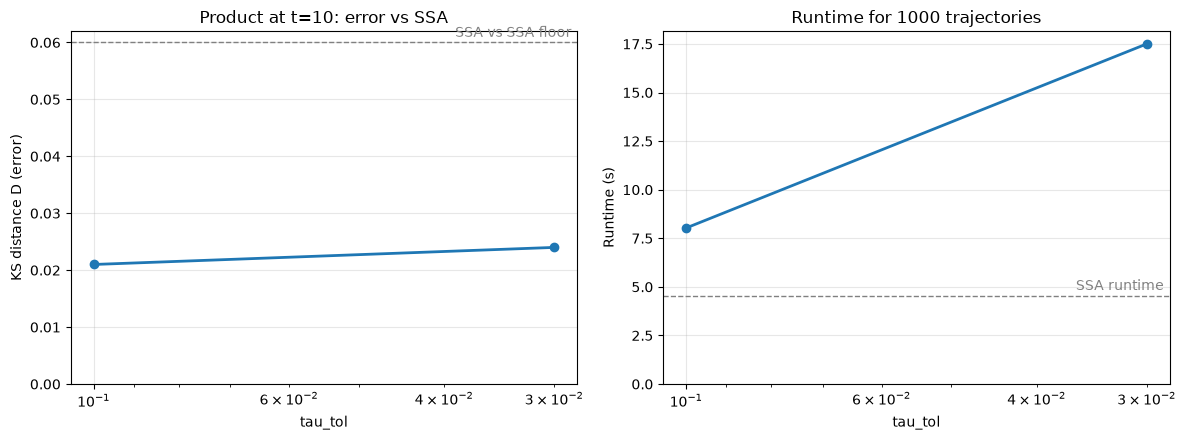

In [14]:
fig, (ax_err, ax_time) = plt.subplots(1, 2, figsize=(12, 4.5))

# error vs tolerance, with the SSA vs SSA noise floor as a reference line
ax_err.plot(tols, [ks_dist[tol] for tol in tols], marker='o', linewidth=2)
ax_err.axhline(ks_floor.statistic, color='gray', linestyle='--', linewidth=1)
ax_err.annotate('SSA vs SSA floor', xy=(1, ks_floor.statistic), xycoords=('axes fraction', 'data'),
                xytext=(-4, 4), textcoords='offset points', ha='right', color='gray')
ax_err.set_xscale('log')
ax_err.set_xlabel('tau_tol')
ax_err.set_ylabel('KS distance D (error)')
ax_err.set_title(f'{species} at t={end_t}: error vs SSA')
ax_err.set_ylim(bottom=0)

# runtime vs tolerance, SSA runtime as a reference line
ax_time.plot(tols, [hybrid_times[tol] for tol in tols], marker='o', linewidth=2)
ax_time.axhline(ssa_time, color='gray', linestyle='--', linewidth=1)
ax_time.annotate('SSA runtime', xy=(1, ssa_time), xycoords=('axes fraction', 'data'),
                 xytext=(-4, 4), textcoords='offset points', ha='right', color='gray')
ax_time.set_xscale('log')
ax_time.set_xlabel('tau_tol')
ax_time.set_ylabel('Runtime (s)')
ax_time.set_title(f'Runtime for {num_traj} trajectories')
ax_time.set_ylim(bottom=0)

for ax in (ax_err, ax_time):
    ax.invert_xaxis()  # tighter tolerance to the right
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

***
## SSA Self-Convergence
***
Independent SSA runs of the same size should overlap more as N grows. The N where they are almost the same is the N to use for the sweep.

### Config

In [15]:
from itertools import combinations

hist_Ns = [100, 1000, 10000]  # ensemble sizes to try, smallest first
n_runs = 3                    # independent SSA runs per N (one box each)

### Helpers

In [16]:
def run_ssa_ensemble(n):
    """Run n SSA trajectories to end_t and return the final count of `species` for each."""
    sim = gillespy2.Simulation(model, number_of_trajectories=n, dt=dt, end_t=end_t, solver="SSA")
    vals = []
    for traj in range(n):
        sim.reset()  # reset the simulation after each run
        prev_t = -1
        while sim.get_time() < sim.end_t:
            t = sim.get_time()
            if t == prev_t:
                raise RuntimeError("Time is not advancing")
            prev_t = t
            sim.run_until(sim.get_time() + sim.dt)
        vals.append(sim.get_species(species))
    return np.array(vals)


def run_hybrid_ensemble(n, tol):
    """Run n Tau-Hybrid trajectories to end_t with tau_tol=tol and return the final count of `species` for each."""
    sim = gillespy2.Simulation(model, number_of_trajectories=n, dt=dt, end_t=end_t, solver="HYBRID")
    vals = []
    for traj in range(n):
        sim.reset()  # reset the simulation after each run
        prev_t = -1
        while sim.get_time() < sim.end_t:
            t = sim.get_time()
            if t == prev_t:
                raise RuntimeError("Time is not advancing")
            prev_t = t
            # call the solver directly so tau_tol reaches it (Simulation.run_until doesn't forward it)
            sim.solver.run_until(sim.get_time() + sim.dt, tau_tol=tol)
        vals.append(sim.get_species(species))
    return np.array(vals)


def plot_overlapping_boxes(groups, labels, title):
    """Horizontal box plots drawn on the same row so they overlap, one color per group.
    When the groups come from the same distribution the boxes line up into one."""
    plt.figure(figsize=(9, 3))
    box = plt.boxplot(groups, positions=[1] * len(groups), widths=0.5,
                      orientation='horizontal', patch_artist=True, showmeans=True)
    for r in range(len(groups)):
        color = f'C{r}'
        box['boxes'][r].set(facecolor=color, alpha=0.3, edgecolor=color, linewidth=1.5)
        box['medians'][r].set(color=color, linewidth=2)
        box['means'][r].set(marker='D', markerfacecolor=color, markeredgecolor='black')
        box['fliers'][r].set(markeredgecolor=color)
        for part in ('whiskers', 'caps'):
            for line in box[part][2 * r:2 * r + 2]:
                line.set(color=color, linewidth=1.5)
    plt.yticks([])
    plt.xlabel(f'{species} at t={end_t}')
    plt.title(title)
    plt.legend(box['boxes'], labels, loc='upper right')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

### Box Plots

N=100: max D=0.100, mean D=0.087, run means=[43.6, 44.2, 43.3], time=1.3s


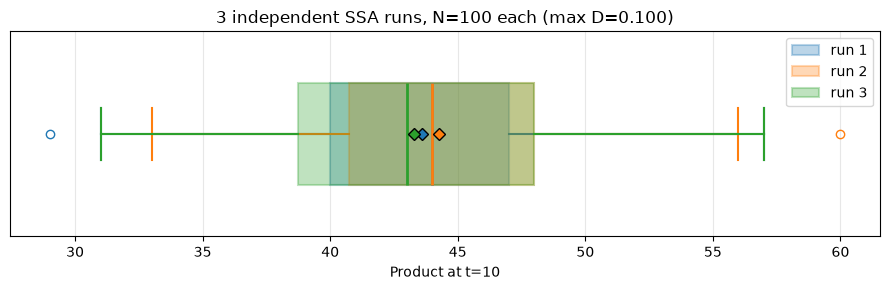

N=1000: max D=0.049, mean D=0.038, run means=[44.1, 44.1, 44.4], time=13.8s


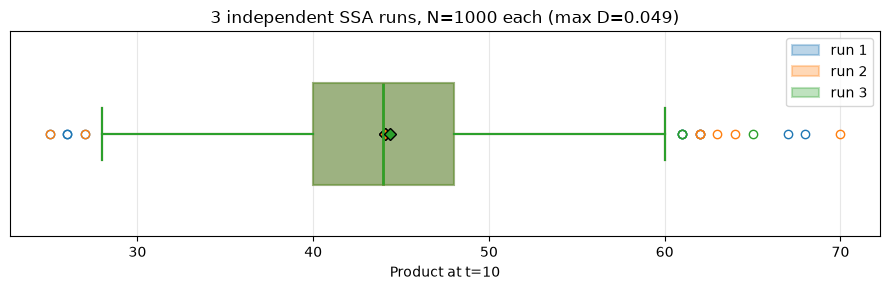

N=10000: max D=0.010, mean D=0.010, run means=[44.3, 44.4, 44.4], time=137.7s


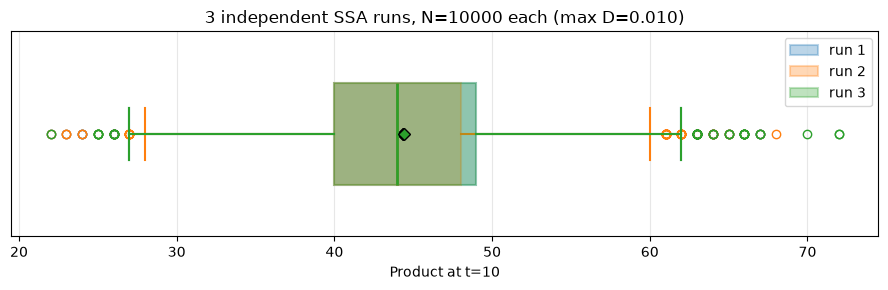

In [17]:
ssa_runs = {}  # ssa_runs[N] = list of n_runs arrays
for N in hist_Ns:
    start = time.perf_counter()
    ssa_runs[N] = [run_ssa_ensemble(N) for _ in range(n_runs)]
    elapsed = time.perf_counter() - start

    # how far apart the runs are: KS distance D for every pair of runs
    pair_d = [ks_2samp(a, b).statistic for a, b in combinations(ssa_runs[N], 2)]
    means = [run.mean() for run in ssa_runs[N]]
    print(f"N={N}: max D={max(pair_d):.3f}, mean D={np.mean(pair_d):.3f}, "
          f"run means={[round(float(m), 1) for m in means]}, time={elapsed:.1f}s")

    plot_overlapping_boxes(ssa_runs[N], [f'run {r + 1}' for r in range(n_runs)],
                           f'{n_runs} independent SSA runs, N={N} each (max D={max(pair_d):.3f})')

***
## Tau-Hybrid Self-Convergence
***
The same check as the SSA section, for Tau-Hybrid at one fixed tau_tol. Independent runs should line up as N grows.

### Config

In [18]:
hybrid_tol = 0.03        # tau_tol for the hybrid self-convergence runs (the solver default)
hybrid_Ns = [100, 1000]  # ensemble sizes for the hybrid runs; check the printed time before adding larger N

### Box Plots

N=100: max D=0.120, mean D=0.093, run means=[43.5, 44.6, 44.0], time=5.3s


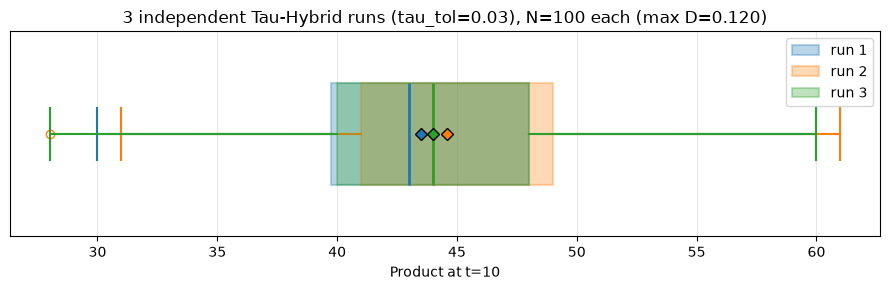

N=1000: max D=0.041, mean D=0.031, run means=[44.0, 44.1, 43.9], time=53.2s


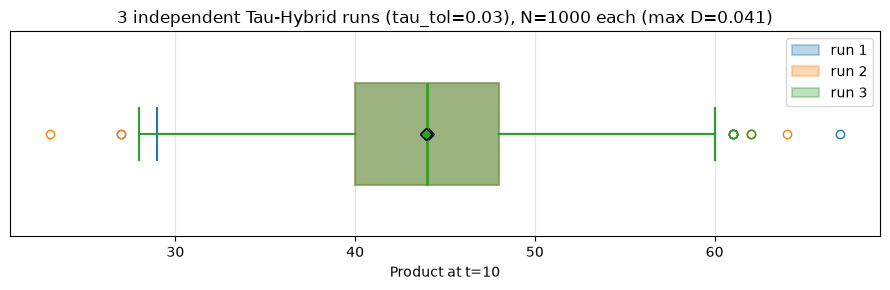

In [19]:
hybrid_runs = {}  # hybrid_runs[N] = list of n_runs arrays
for N in hybrid_Ns:
    start = time.perf_counter()
    hybrid_runs[N] = [run_hybrid_ensemble(N, hybrid_tol) for _ in range(n_runs)]
    elapsed = time.perf_counter() - start

    # how far apart the runs are: KS distance D for every pair of runs
    pair_d = [ks_2samp(a, b).statistic for a, b in combinations(hybrid_runs[N], 2)]
    means = [run.mean() for run in hybrid_runs[N]]
    print(f"N={N}: max D={max(pair_d):.3f}, mean D={np.mean(pair_d):.3f}, "
          f"run means={[round(float(m), 1) for m in means]}, time={elapsed:.1f}s")

    plot_overlapping_boxes(hybrid_runs[N], [f'run {r + 1}' for r in range(n_runs)],
                           f'{n_runs} independent Tau-Hybrid runs (tau_tol={hybrid_tol}), N={N} each '
                           f'(max D={max(pair_d):.3f})')

***
## SSA vs Tau-Hybrid
***
SSA and Tau-Hybrid on the same row for each tau_tol. A large tau_tol should not match SSA; as tau_tol shrinks the boxes should move together.

### Config

In [20]:
compare_tols = [0.5, 0.1, 0.03, 0.01]  # tau_tol values, largest (least accurate) first
compare_N = 1000                        # trajectories per ensemble for the comparison

### Box Plots

tau_tol=0.5: D=0.020, p=0.988, SSA mean=44.1, hybrid mean=43.9, time=7.9s


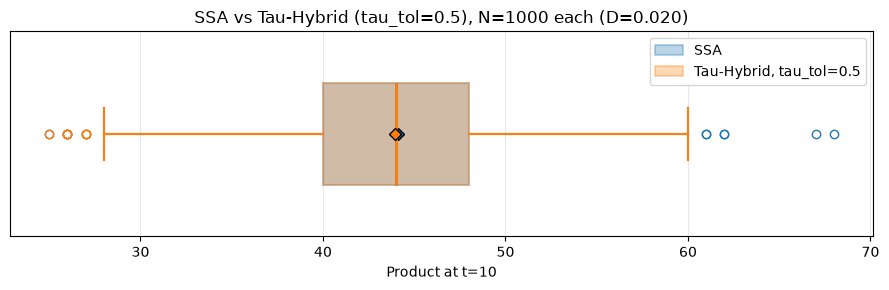

tau_tol=0.1: D=0.029, p=0.795, SSA mean=44.1, hybrid mean=43.8, time=8.2s


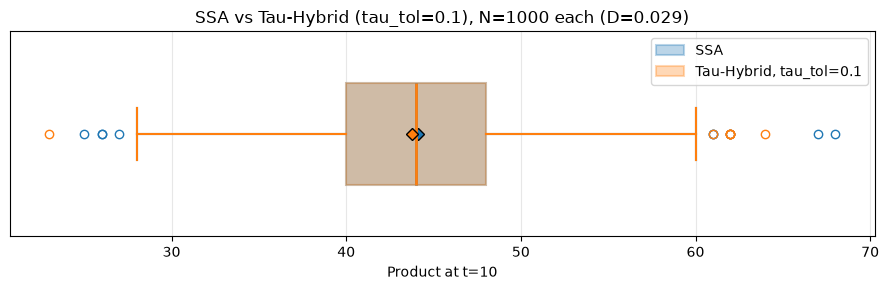

tau_tol=0.03: D=0.018, p=0.997, SSA mean=44.1, hybrid mean=44.0, time=17.8s


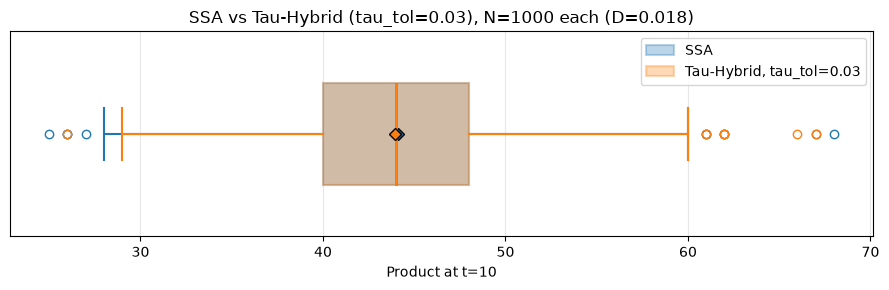

tau_tol=0.01: D=0.035, p=0.573, SSA mean=44.1, hybrid mean=44.1, time=20.5s


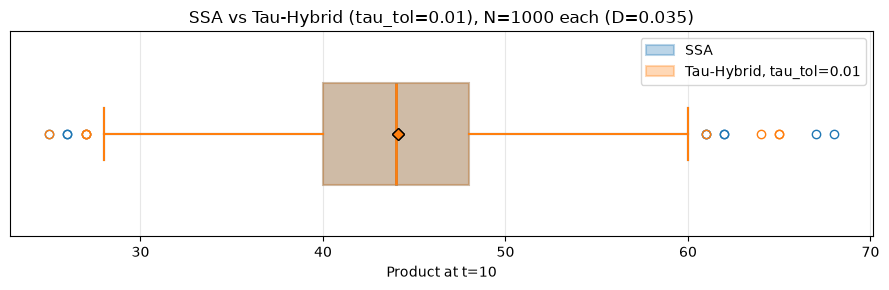

In [21]:
# SSA reference: reuse a run from the SSA self-convergence section if that size was run, else run it now
ssa_ref = ssa_runs[compare_N][0] if compare_N in ssa_runs else run_ssa_ensemble(compare_N)

compare_vals = {}  # compare_vals[tol] = Tau-Hybrid final counts at that tau_tol
for tol in compare_tols:
    start = time.perf_counter()
    compare_vals[tol] = run_hybrid_ensemble(compare_N, tol)
    elapsed = time.perf_counter() - start

    res = ks_2samp(ssa_ref, compare_vals[tol])
    print(f"tau_tol={tol}: D={res.statistic:.3f}, p={res.pvalue:.3f}, "
          f"SSA mean={ssa_ref.mean():.1f}, hybrid mean={compare_vals[tol].mean():.1f}, time={elapsed:.1f}s")

    plot_overlapping_boxes([ssa_ref, compare_vals[tol]], ['SSA', f'Tau-Hybrid, tau_tol={tol}'],
                           f'SSA vs Tau-Hybrid (tau_tol={tol}), N={compare_N} each (D={res.statistic:.3f})')